# 05 – Baseline : le score à battre

## Leçon 1 – Pourquoi commencer par un modèle « bête » ?

Imagine qu'on entraîne un modèle de machine learning sophistiqué et qu'il obtienne un score de 0,05. C'est bien ? C'est nul ? **Impossible à dire sans point de comparaison.**

Une **baseline** (*référence*) est une méthode très simple, sans machine learning, qu'on calcule **avant** le vrai modèle. Elle répond à la question : *« qu'est-ce qu'on obtient avec du bon sens et un tableau croisé dynamique ? »*

Ensuite, le modèle de ML n'a d'intérêt que s'il **bat nettement** la baseline. S'il ne la bat pas, il est inutilement compliqué (et ça arrive plus souvent qu'on ne croit !).

> En prévision de demande, tu connais déjà ça : la prévision « naïve » (*les ventes de la semaine prochaine = celles de la même semaine l'an dernier*) est la baseline que tout modèle de forecast doit battre.

**Notre baseline :** *« le risque de feu d'une commune un jour donné = le taux de feu historique de cette commune pour ce mois-là »*. Exemple : si Martigues a eu des feux 20 % des jours de juillet entre 2016 et 2020, on prédit 20 % pour chaque jour de juillet 2021. Elle capture la **géographie** et la **saison**, mais ignore complètement la **météo du jour**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

df = pd.read_csv("../data/processed/features_13.csv", dtype={"code": str}, parse_dates=["jour"])
df["annee"] = df["jour"].dt.year
print(df.shape)

(434707, 23)


Nouveauté : `from sklearn.metrics import ...`. **scikit-learn** (`sklearn`) est LA bibliothèque de machine learning en Python. On importe ici seulement deux fonctions de mesure ; on utilisera ses modèles au prochain notebook.

## Leçon 2 – Le découpage train / validation / test

Pour savoir si une méthode prédit bien, il faut la juger sur des données **qu'elle n'a pas vues**. Sinon, c'est comme donner les réponses de l'examen avant l'examen.

On coupe donc les données en 3 :

| Jeu | Années | Rôle |
|---|---|---|
| **train** (entraînement) | 2016 → 2020 | on y **apprend** (ici : on calcule les taux historiques) |
| **validation** | 2021 → 2022 | on y **compare** les méthodes et on fait nos choix |
| **test** | 2023 → 2025 | on n'y touche **qu'une seule fois, à la toute fin**, pour le score final |

### Pourquoi couper par le temps, et pas au hasard ?
Avec un tirage au hasard, on pourrait apprendre sur le 15 juillet 2022 et tester sur le 14 juillet 2022 : la sécheresse de cet été-là « fuirait » d'un jeu à l'autre, et le score serait trop optimiste. Dans la vraie vie, on prédit toujours **le futur à partir du passé**. Le découpage temporel reproduit exactement cette situation.

### Pourquoi un jeu de test « sous clé » ?
À force de comparer des méthodes sur la validation et de garder la meilleure, on finit par s'adapter à ces 2 années-là. Le test, jamais consulté, donne un score **honnête**. Dans ce notebook, on **ne regarde pas** le test.

In [2]:
train = df[df["annee"] <= 2020]
valid = df[df["annee"].between(2021, 2022)]
test  = df[df["annee"] >= 2023]   # sous clé : on n'y touche pas avant la fin du projet

for nom, d in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{nom:6} {len(d):>7} lignes  {d['feu'].sum():>5} feux  taux = {d['feu'].mean():.2%}")

train   217413 lignes   1069 feux  taux = 0.49%
valid    86870 lignes    683 feux  taux = 0.79%
test    130424 lignes    728 feux  taux = 0.56%


`f"..."` est une **f-string** : on glisse des variables entre `{}` dans le texte. `:>7` aligne à droite sur 7 caractères, `:.2%` affiche en pourcentage avec 2 décimales.

**Observation importante :** le taux de feu n'est pas le même partout (≈ 0,49 % en train, ≈ 0,79 % en validation). La validation contient **2022**, année de sécheresse record. Garde ça en tête : c'est justement le genre d'année où une méthode qui ignore la météo devrait souffrir.

## Leçon 3 – Comment mesurer la qualité d'une prédiction de risque ?

Notre méthode produit un **score** pour chaque ligne (une probabilité de feu). Pour décider, on choisit un **seuil** : au-dessus → « alerte », en dessous → « pas d'alerte ». On compare ensuite aux feux réels :

| | Feu réel | Pas de feu |
|---|---|---|
| **Alerte** | ✅ vrai positif | ❌ fausse alerte |
| **Pas d'alerte** | ❌ feu raté | ✅ vrai négatif |

Deux questions en découlent :
- **Précision** = parmi mes alertes, quelle part étaient de vrais feux ? *(est-ce que je crie au loup pour rien ?)*
- **Rappel** (*recall*) = parmi les vrais feux, quelle part avais-je signalée ? *(est-ce que je rate des feux ?)*

C'est un compromis : baisser le seuil attrape plus de feux (rappel ↑) mais déclenche plus de fausses alertes (précision ↓).

### Pourquoi pas l'accuracy (le % de bonnes réponses) ?
Avec 0,6 % de feux, un modèle qui dit **toujours** « pas de feu » a 99,4 % d'accuracy… et ne sert à rien. L'accuracy est trompeuse quand les classes sont déséquilibrées.

### La PR-AUC
La **courbe précision-rappel** trace la précision et le rappel pour **tous les seuils possibles**. L'aire sous cette courbe, la **PR-AUC** (calculée par `average_precision_score`), résume la qualité en un seul nombre :
- un score **au hasard** obtient une PR-AUC ≈ **le taux de feu** (≈ 0,008 ici) ;
- un score **parfait** obtient **1**.

Bonne nouvelle : la PR-AUC ne dépend que de **l'ordre** des scores (qui est plus risqué que qui), pas de leur valeur exacte. N'importe quel nombre qui « monte avec le risque » peut donc servir de score.

On écrit une petite **fonction** pour évaluer chaque méthode et garder les résultats dans un tableau :

In [3]:
resultats = []

def evaluer(nom, y_vrai, score):
    pr_auc = average_precision_score(y_vrai, score)
    resultats.append({"méthode": nom, "PR-AUC": round(pr_auc, 4)})
    print(f"{nom:40} PR-AUC = {pr_auc:.4f}")

## Étape 1 – La référence absolue : le hasard

Un score **constant** (le même chiffre pour toutes les lignes) ne sait distinguer aucun jour d'un autre. C'est le plancher.

In [4]:
score_constant = np.full(len(valid), train["feu"].mean())
evaluer("Constante (aucune information)", valid["feu"], score_constant)

Constante (aucune information)           PR-AUC = 0.0079


`np.full(n, x)` crée un tableau de `n` cases remplies avec `x`. Comme prévu, la PR-AUC ≈ taux de feu de la validation (≈ 0,0079).

## Étape 2 – Baselines à une seule information

Avant de combiner, regardons ce que chaque information apporte **seule**. Le principe est toujours le même :
1. on calcule un taux de feu **sur le train uniquement** (`groupby` + `mean`) ;
2. on **reporte** ce taux sur les lignes de validation avec `.map()` (qui remplace chaque valeur par celle trouvée dans la table de correspondance – une RECHERCHEV).

⚠️ On calcule les taux sur le **train** et jamais sur la validation : sinon on utiliserait les feux de 2021-2022 pour prédire 2021-2022 (fuite de données, cf. notebook 04).

In [5]:
taux_mois = train.groupby("mois")["feu"].mean()
evaluer("Taux historique par mois", valid["feu"], valid["mois"].map(taux_mois))

taux_commune = train.groupby("code")["feu"].mean()
evaluer("Taux historique par commune", valid["feu"], valid["code"].map(taux_commune))

Taux historique par mois                 PR-AUC = 0.0179


Taux historique par commune              PR-AUC = 0.0273


Les deux battent nettement le hasard. Et la **commune** apporte plus que le **mois** : *où* compte encore plus que *quand*.

## Étape 3 – LA baseline : commune × mois

On combine les deux : un taux par couple (commune, mois). `groupby(["code", "mois"])` crée un groupe par combinaison, soit 119 × 12 = 1 428 taux.

Pour reporter un taux qui dépend de **deux** colonnes, `.map()` ne suffit plus : on fait une **jointure** (`merge`), comme au notebook 02.

In [6]:
taux_commune_mois = train.groupby(["code", "mois"])["feu"].mean().rename("score_baseline")

valid = valid.merge(taux_commune_mois, left_on=["code", "mois"], right_index=True, how="left")
print("lignes sans score :", valid["score_baseline"].isna().sum())   # attendu : 0

evaluer("BASELINE : taux commune × mois", valid["feu"], valid["score_baseline"])

lignes sans score : 0
BASELINE : taux commune × mois           PR-AUC = 0.0484


`right_index=True` : dans `taux_commune_mois`, le couple (code, mois) n'est pas une colonne mais **l'index** (les étiquettes des lignes, créées par le `groupby`). On dit à `merge` d'aller le chercher là.

**C'est notre baseline officielle.** Environ **6 fois mieux que le hasard**, avec juste un tableau croisé dynamique !

## Étape 4 – Et la météo seule ?

Rappelle-toi : la PR-AUC n'a besoin que d'un score qui « monte avec le risque ». On peut donc tester directement une feature météo comme score :
- `jours_sans_pluie` : plus c'est grand, plus c'est risqué ;
- `bilan_hydrique_30j` : plus c'est **négatif**, plus c'est risqué → on prend **moins** le bilan pour que le score monte avec le risque.

In [7]:
evaluer("Jours sans pluie seul", valid["feu"], valid["jours_sans_pluie"])
evaluer("Bilan hydrique 30 j seul (inversé)", valid["feu"], -valid["bilan_hydrique_30j"])

Jours sans pluie seul                    PR-AUC = 0.0127


Bilan hydrique 30 j seul (inversé)       PR-AUC = 0.0184


La météo seule fait mieux que le hasard, mais **beaucoup moins bien** que la baseline commune × mois. Pourquoi ? Parce qu'un jour sec à Marseille et un jour sec dans une petite commune agricole de Camargue n'ont pas du tout le même risque. La météo dit **quand**, la commune dit **où**.

👉 C'est exactement ce que le modèle de ML devra faire : **combiner** le où, le quand et la météo, ce qu'aucune règle simple ne fait. S'il y arrive, il battra la baseline.

## Étape 5 – Le classement

On transforme notre liste de résultats en tableau, trié du meilleur au moins bon :

In [8]:
tableau = pd.DataFrame(resultats).sort_values("PR-AUC", ascending=False)
tableau["× hasard"] = (tableau["PR-AUC"] / valid["feu"].mean()).round(1)
tableau

,méthode,PR-AUC,× hasard
3,BASELINE : taux commune × mois,0.0484,6.2
2,Taux historique par commune,0.0273,3.5
5,Bilan hydrique 30 j seul (inversé),0.0184,2.3
1,Taux historique par mois,0.0179,2.3
4,Jours sans pluie seul,0.0127,1.6
0,Constante (aucune information),0.0079,1.0


## Étape 6 – Visualiser : la courbe précision-rappel

`precision_recall_curve` calcule précision et rappel pour tous les seuils. On trace les courbes de nos méthodes principales : **plus une courbe est haute et à droite, meilleure est la méthode**.

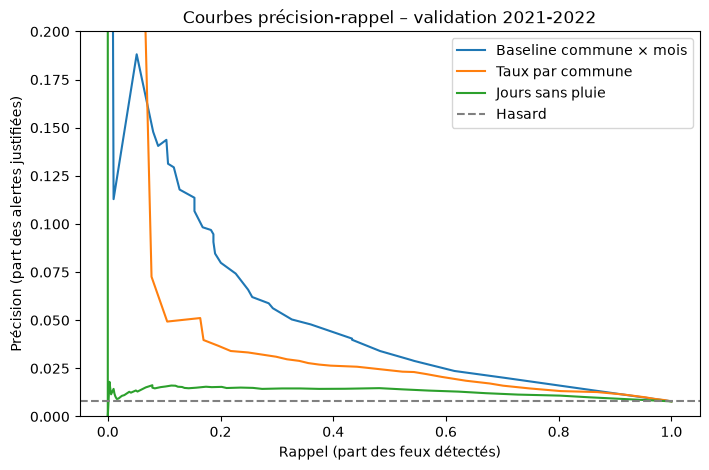

In [9]:
plt.figure(figsize=(8, 5))
for nom, score in [
    ("Baseline commune × mois", valid["score_baseline"]),
    ("Taux par commune", valid["code"].map(taux_commune)),
    ("Jours sans pluie", valid["jours_sans_pluie"]),
]:
    precision, rappel, _ = precision_recall_curve(valid["feu"], score)
    plt.plot(rappel, precision, label=nom)

plt.axhline(valid["feu"].mean(), color="grey", linestyle="--", label="Hasard")
plt.xlabel("Rappel (part des feux détectés)")
plt.ylabel("Précision (part des alertes justifiées)")
plt.title("Courbes précision-rappel – validation 2021-2022")
plt.ylim(0, 0.2)
plt.legend()
plt.show()

`_` est une convention Python pour dire « cette valeur ne m'intéresse pas » (ici, la liste des seuils).

Les courbes sont **basses** : même la meilleure méthode a une précision de quelques % seulement. C'est normal pour un événement aussi rare et aussi aléatoire qu'un départ de feu (il faut une étincelle humaine !). On ne cherche pas à prédire *le* feu, mais à **classer les jours et les communes par niveau de risque**.

## Étape 7 – Une mesure parlante : « si on surveille le top X % »

La PR-AUC est abstraite. Pour expliquer le résultat à un pompier (ou à un manager !), une question concrète :

> *« Si on renforce la surveillance sur les 5 % de couples commune × jour les plus risqués, quelle part des feux aurait-on couverte ? »*

On trie la validation par score décroissant, on garde le haut du classement, et on compte les feux qu'il contient.

In [10]:
def part_feux_couverte(d, colonne_score, part):
    n = int(len(d) * part)
    top = d.sort_values(colonne_score, ascending=False).head(n)
    return top["feu"].sum() / d["feu"].sum()

for part in [0.01, 0.05, 0.10, 0.20]:
    couverture = part_feux_couverte(valid, "score_baseline", part)
    print(f"Top {part:>4.0%} des lignes → {couverture:.0%} des feux")

Top   1% des lignes → 15% des feux
Top   5% des lignes → 32% des feux
Top  10% des lignes → 46% des feux
Top  20% des lignes → 61% des feux


**Lecture :** en surveillant seulement 5 % des couples commune × jour, la baseline couvre déjà environ un tiers des feux. C'est l'indicateur qu'on suivra aussi pour le modèle : **à effort de surveillance égal, combien de feux en plus ?**

**À toi de jouer :** calcule la même chose avec `jours_sans_pluie` comme score. Est-ce cohérent avec le classement PR-AUC ?

In [11]:
# Correction : on compare les deux scores côte à côte
comparaison = pd.DataFrame({
    "part surveillée": ["1 %", "5 %", "10 %", "20 %"],
    "baseline commune × mois": [part_feux_couverte(valid, "score_baseline", p) for p in [0.01, 0.05, 0.10, 0.20]],
    "jours sans pluie": [part_feux_couverte(valid, "jours_sans_pluie", p) for p in [0.01, 0.05, 0.10, 0.20]],
})
comparaison.style.format({"baseline commune × mois": "{:.0%}", "jours sans pluie": "{:.0%}"})

,part surveillée,baseline commune × mois,jours sans pluie
0,1 %,15%,1%
1,5 %,32%,10%
2,10 %,46%,19%
3,20 %,61%,37%


### Correction de l'exercice

`[... for p in [...]]` est une **compréhension de liste** : une boucle `for` écrite en une ligne, qui fabrique une liste (ici, une couverture par part surveillée). `.style.format(...)` affiche joliment les nombres en pourcentages, sans les modifier.

**Ce qu'on observe :**

| Part surveillée | Baseline | Jours sans pluie |
|---|---|---|
| 1 % | 15 % | **1 %** 😮 |
| 5 % | 32 % | 10 % |
| 10 % | 46 % | 19 % |
| 20 % | 61 % | 37 % |

1. **C'est cohérent avec la PR-AUC** : la baseline est meilleure partout, comme le classement l'annonçait.
2. **Surprise : au top 1 %, « jours sans pluie » fait moins bien que le hasard** (1 % des feux pour 1 % des lignes). Les plus longues sécheresses (> 42 jours, le top 1 %) ne sont pas les jours les plus dangereux ! On l'avait déjà entrevu au notebook 04 : le taux de feu **redescend** au-delà de 60 jours sans pluie. Hypothèses : ces longues périodes sèches arrivent aussi en hiver (froid, végétation peu inflammable), ou en fin d'été quand ce qui pouvait brûler a déjà brûlé.

**Leçon :** une relation n'est pas forcément « toujours plus = toujours plus risqué ». Une règle simple ne capte pas ces effets, alors qu'un modèle à base d'arbres saura les découvrir (par exemple : « beaucoup de jours sans pluie **ET** en été »). C'est un argument de plus pour le notebook 06.


## Étape 8 – Sauvegarder la référence

On garde le tableau des résultats pour pouvoir y ajouter ceux du modèle au prochain notebook.

In [12]:
tableau.to_csv("../data/processed/resultats_validation.csv", index=False)
tableau

,méthode,PR-AUC,× hasard
3,BASELINE : taux commune × mois,0.0484,6.2
2,Taux historique par commune,0.0273,3.5
5,Bilan hydrique 30 j seul (inversé),0.0184,2.3
1,Taux historique par mois,0.0179,2.3
4,Jours sans pluie seul,0.0127,1.6
0,Constante (aucune information),0.0079,1.0


## ✅ Validation de la baseline

On vérifie qu'elle remplit bien son rôle de référence :

| Critère | Vérifié ? |
|---|---|
| Calculée **uniquement sur le train** (pas de fuite) | ✅ taux 2016-2020 appliqués à 2021-2022 |
| Un score pour **chaque** ligne de validation | ✅ 0 ligne sans score |
| Nettement meilleure que le hasard | ✅ PR-AUC 0,048 = ×6,2 |
| Meilleure que chaque information prise seule | ✅ devant commune seule, mois seul, météo seule |
| Facile à expliquer | ✅ « taux de feu historique de la commune ce mois-ci » |
| Jeu de test intact | ✅ jamais consulté |

**Baseline validée. La barre à franchir pour le modèle :**
- **PR-AUC > 0,048** sur la validation 2021-2022 ;
- **plus de 32 % des feux couverts** en surveillant 5 % des couples commune × jour.


## Récap du notebook

1. **Baseline** = méthode simple à battre ; sans elle, un score de modèle ne veut rien dire.
2. **Découpage temporel** train (≤ 2020) / validation (2021-22) / test (2023-25, sous clé) : on prédit le futur avec le passé.
3. **Précision** (mes alertes sont-elles justes ?) vs **rappel** (est-ce que je rate des feux ?) ; **PR-AUC** pour résumer, car l'accuracy est trompeuse avec 0,6 % de positifs.
4. Les taux historiques sont calculés **sur le train uniquement**.
5. Résultat : la baseline commune × mois fait **≈ 6× mieux que le hasard** et couvre **≈ 1/3 des feux en surveillant 5 % des lignes**. La météo seule fait moins bien… mais elle contient une information que la baseline ignore.

**Prochaine étape (06) :** le vrai modèle, `HistGradientBoostingClassifier`, qui va combiner commune, saison et météo. Objectif : battre la baseline sur la validation.